In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jeanmidev/smart-meters-in-london/darksky_parameters_documentation.html
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/weather_hourly_darksky.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/acorn_details.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/uk_bank_holidays.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/weather_daily_darksky.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/daily_dataset.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/informations_households.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset/block_97.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset/block_27.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset/block_55.csv
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset/block_0.csv
/kaggle/input/datasets/jeanmi

In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

import warnings
warnings.filterwarnings("ignore")

In [4]:
import os

DATA_DIR = "/kaggle/input/datasets/jeanmidev/smart-meters-in-london"

files = os.listdir(DATA_DIR)

for file in files:
    print(file)

darksky_parameters_documentation.html
weather_hourly_darksky.csv
hhblock_dataset
halfhourly_dataset
acorn_details.csv
uk_bank_holidays.csv
weather_daily_darksky.csv
daily_dataset
daily_dataset.csv
informations_households.csv


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("\nFOLDER:", root)

    for file in files:
        print("   ", file)


FOLDER: /kaggle/input

FOLDER: /kaggle/input/datasets

FOLDER: /kaggle/input/datasets/jeanmidev

FOLDER: /kaggle/input/datasets/jeanmidev/smart-meters-in-london
    darksky_parameters_documentation.html
    weather_hourly_darksky.csv
    acorn_details.csv
    uk_bank_holidays.csv
    weather_daily_darksky.csv
    daily_dataset.csv
    informations_households.csv

FOLDER: /kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset

FOLDER: /kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset
    block_97.csv
    block_27.csv
    block_55.csv
    block_0.csv
    block_2.csv
    block_9.csv
    block_34.csv
    block_60.csv
    block_7.csv
    block_43.csv
    block_99.csv
    block_87.csv
    block_89.csv
    block_47.csv
    block_106.csv
    block_92.csv
    block_54.csv
    block_8.csv
    block_28.csv
    block_107.csv
    block_57.csv
    block_82.csv
    block_78.csv
    block_31.csv
    block_52.csv
    block_21.csv
    block_53.csv


In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "/kaggle/input/datasets/jeanmidev/smart-meters-in-london"

BLOCK_DIR = os.path.join(
    DATA_DIR,
    "hhblock_dataset",
    "hhblock_dataset"
)

print(DATA_DIR)
print(BLOCK_DIR)

/kaggle/input/datasets/jeanmidev/smart-meters-in-london
/kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset


In [7]:
block_files = os.listdir(BLOCK_DIR)

print("Number of block files:", len(block_files))

print(block_files[:20])

Number of block files: 112
['block_97.csv', 'block_27.csv', 'block_55.csv', 'block_0.csv', 'block_2.csv', 'block_9.csv', 'block_34.csv', 'block_60.csv', 'block_7.csv', 'block_43.csv', 'block_99.csv', 'block_87.csv', 'block_89.csv', 'block_47.csv', 'block_106.csv', 'block_92.csv', 'block_54.csv', 'block_8.csv', 'block_28.csv', 'block_107.csv']


In [8]:
first_file = os.path.join(
    BLOCK_DIR,
    block_files[0]
)

block = pd.read_csv(first_file)

print("Shape:", block.shape)

Shape: (31993, 50)


In [9]:
block.head()

,LCLid,day,hh_0,hh_1,hh_2,hh_3,hh_4,hh_5,hh_6,hh_7,...,hh_38,hh_39,hh_40,hh_41,hh_42,hh_43,hh_44,hh_45,hh_46,hh_47
0,MAC000047,2011-12-09,0.114,0.074,0.107,0.098,0.090,0.106,0.077,0.115,...,0.097,0.134,0.295,0.063,0.072,0.040,0.074,0.051,0.065,0.068
1,MAC000047,2011-12-10,0.035,0.082,0.050,0.064,0.059,0.048,0.082,0.044,...,0.120,0.115,0.106,0.135,0.077,0.104,0.096,0.076,0.106,0.076
2,MAC000047,2011-12-11,0.103,0.085,0.083,0.113,0.072,0.096,0.098,0.084,...,0.191,0.163,0.203,0.182,0.168,0.145,0.074,0.114,0.078,0.096
3,MAC000047,2011-12-12,0.107,0.072,0.109,0.088,0.099,0.098,0.075,0.120,...,0.160,0.195,0.156,0.105,0.125,0.076,0.111,0.074,0.098,0.104
4,MAC000047,2011-12-13,0.073,0.108,0.084,0.101,0.095,0.078,0.118,0.080,...,0.181,0.130,0.146,0.116,0.113,0.110,0.082,0.120,0.079,0.101


In [10]:
block.columns.tolist()

['LCLid',
 'day',
 'hh_0',
 'hh_1',
 'hh_2',
 'hh_3',
 'hh_4',
 'hh_5',
 'hh_6',
 'hh_7',
 'hh_8',
 'hh_9',
 'hh_10',
 'hh_11',
 'hh_12',
 'hh_13',
 'hh_14',
 'hh_15',
 'hh_16',
 'hh_17',
 'hh_18',
 'hh_19',
 'hh_20',
 'hh_21',
 'hh_22',
 'hh_23',
 'hh_24',
 'hh_25',
 'hh_26',
 'hh_27',
 'hh_28',
 'hh_29',
 'hh_30',
 'hh_31',
 'hh_32',
 'hh_33',
 'hh_34',
 'hh_35',
 'hh_36',
 'hh_37',
 'hh_38',
 'hh_39',
 'hh_40',
 'hh_41',
 'hh_42',
 'hh_43',
 'hh_44',
 'hh_45',
 'hh_46',
 'hh_47']

In [11]:
block.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31993 entries, 0 to 31992
Data columns (total 50 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   LCLid   31993 non-null  object 
 1   day     31993 non-null  object 
 2   hh_0    31993 non-null  float64
 3   hh_1    31993 non-null  float64
 4   hh_2    31993 non-null  float64
 5   hh_3    31993 non-null  float64
 6   hh_4    31993 non-null  float64
 7   hh_5    31993 non-null  float64
 8   hh_6    31993 non-null  float64
 9   hh_7    31993 non-null  float64
 10  hh_8    31993 non-null  float64
 11  hh_9    31993 non-null  float64
 12  hh_10   31993 non-null  float64
 13  hh_11   31993 non-null  float64
 14  hh_12   31993 non-null  float64
 15  hh_13   31993 non-null  float64
 16  hh_14   31993 non-null  float64
 17  hh_15   31993 non-null  float64
 18  hh_16   31993 non-null  float64
 19  hh_17   31993 non-null  float64
 20  hh_18   31993 non-null  float64
 21  hh_19   31993 non-null  float64
 22

In [12]:
print(
    "Households:",
    block["LCLid"].nunique()
)

Households: 50


In [13]:
print(
    block["LCLid"].unique()[:20]
)

['MAC000047' 'MAC000362' 'MAC000385' 'MAC000486' 'MAC000507' 'MAC000510'
 'MAC000511' 'MAC000513' 'MAC000541' 'MAC000542' 'MAC000556' 'MAC000684'
 'MAC000690' 'MAC000695' 'MAC000696' 'MAC000718' 'MAC000735' 'MAC000740'
 'MAC000743' 'MAC000746']


In [14]:
block["day"] = pd.to_datetime(
    block["day"]
)

print("Start:", block["day"].min())
print("End:", block["day"].max())

Start: 2011-12-09 00:00:00
End: 2014-02-27 00:00:00


In [15]:
import os
import zipfile
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import GRU
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

import warnings
warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [16]:
DATA_DIR = "/kaggle/input/datasets/jeanmidev/smart-meters-in-london"
DATA_DIR = "/kaggle/input/datasets/jeanmidev/smart-meters-in-london"

print(os.listdir(DATA_DIR))

['darksky_parameters_documentation.html', 'weather_hourly_darksky.csv', 'hhblock_dataset', 'halfhourly_dataset', 'acorn_details.csv', 'uk_bank_holidays.csv', 'weather_daily_darksky.csv', 'daily_dataset', 'daily_dataset.csv', 'informations_households.csv']


In [17]:
BLOCK_DIR = os.path.join(
    DATA_DIR,
    "hhblock_dataset",
    "hhblock_dataset"
)

print(BLOCK_DIR)

/kaggle/input/datasets/jeanmidev/smart-meters-in-london/hhblock_dataset/hhblock_dataset


In [18]:
print(os.listdir(BLOCK_DIR)[:20])

['block_97.csv', 'block_27.csv', 'block_55.csv', 'block_0.csv', 'block_2.csv', 'block_9.csv', 'block_34.csv', 'block_60.csv', 'block_7.csv', 'block_43.csv', 'block_99.csv', 'block_87.csv', 'block_89.csv', 'block_47.csv', 'block_106.csv', 'block_92.csv', 'block_54.csv', 'block_8.csv', 'block_28.csv', 'block_107.csv']


In [19]:
block_files = [
    f for f in os.listdir(BLOCK_DIR)
    if f.endswith(".csv")
]

print("Number of block files:", len(block_files))

print(block_files[:20])

Number of block files: 112
['block_97.csv', 'block_27.csv', 'block_55.csv', 'block_0.csv', 'block_2.csv', 'block_9.csv', 'block_34.csv', 'block_60.csv', 'block_7.csv', 'block_43.csv', 'block_99.csv', 'block_87.csv', 'block_89.csv', 'block_47.csv', 'block_106.csv', 'block_92.csv', 'block_54.csv', 'block_8.csv', 'block_28.csv', 'block_107.csv']


# Read block_0.csv

In [20]:
block_path = os.path.join(
    BLOCK_DIR,
    "block_0.csv"
)

block = pd.read_csv(block_path)

print("Shape:", block.shape)

Shape: (25286, 50)


In [21]:
block.head()

,LCLid,day,hh_0,hh_1,hh_2,hh_3,hh_4,hh_5,hh_6,hh_7,...,hh_38,hh_39,hh_40,hh_41,hh_42,hh_43,hh_44,hh_45,hh_46,hh_47
0,MAC000002,2012-10-13,0.263,0.269,0.275,0.256,0.211,0.136,0.161,0.119,...,0.918,0.278,0.267,0.239,0.230,0.233,0.235,0.188,0.259,0.250
1,MAC000002,2012-10-14,0.262,0.166,0.226,0.088,0.126,0.082,0.123,0.083,...,1.075,0.956,0.821,0.745,0.712,0.511,0.231,0.210,0.278,0.159
2,MAC000002,2012-10-15,0.192,0.097,0.141,0.083,0.132,0.070,0.130,0.074,...,1.164,0.249,0.225,0.258,0.260,0.334,0.299,0.236,0.241,0.237
3,MAC000002,2012-10-16,0.237,0.237,0.193,0.118,0.098,0.107,0.094,0.109,...,0.966,0.172,0.192,0.228,0.203,0.211,0.188,0.213,0.157,0.202
4,MAC000002,2012-10-17,0.157,0.211,0.155,0.169,0.101,0.117,0.084,0.118,...,0.223,0.075,0.230,0.208,0.265,0.377,0.327,0.277,0.288,0.256


In [22]:
print(block.columns.tolist())

['LCLid', 'day', 'hh_0', 'hh_1', 'hh_2', 'hh_3', 'hh_4', 'hh_5', 'hh_6', 'hh_7', 'hh_8', 'hh_9', 'hh_10', 'hh_11', 'hh_12', 'hh_13', 'hh_14', 'hh_15', 'hh_16', 'hh_17', 'hh_18', 'hh_19', 'hh_20', 'hh_21', 'hh_22', 'hh_23', 'hh_24', 'hh_25', 'hh_26', 'hh_27', 'hh_28', 'hh_29', 'hh_30', 'hh_31', 'hh_32', 'hh_33', 'hh_34', 'hh_35', 'hh_36', 'hh_37', 'hh_38', 'hh_39', 'hh_40', 'hh_41', 'hh_42', 'hh_43', 'hh_44', 'hh_45', 'hh_46', 'hh_47']


In [23]:
block.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25286 entries, 0 to 25285
Data columns (total 50 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   LCLid   25286 non-null  object 
 1   day     25286 non-null  object 
 2   hh_0    25286 non-null  float64
 3   hh_1    25286 non-null  float64
 4   hh_2    25286 non-null  float64
 5   hh_3    25286 non-null  float64
 6   hh_4    25286 non-null  float64
 7   hh_5    25286 non-null  float64
 8   hh_6    25286 non-null  float64
 9   hh_7    25286 non-null  float64
 10  hh_8    25286 non-null  float64
 11  hh_9    25286 non-null  float64
 12  hh_10   25286 non-null  float64
 13  hh_11   25286 non-null  float64
 14  hh_12   25286 non-null  float64
 15  hh_13   25286 non-null  float64
 16  hh_14   25286 non-null  float64
 17  hh_15   25286 non-null  float64
 18  hh_16   25286 non-null  float64
 19  hh_17   25286 non-null  float64
 20  hh_18   25286 non-null  float64
 21  hh_19   25286 non-null  float64
 22

In [24]:
block.describe(include="all")

,LCLid,day,hh_0,hh_1,hh_2,hh_3,hh_4,hh_5,hh_6,hh_7,...,hh_38,hh_39,hh_40,hh_41,hh_42,hh_43,hh_44,hh_45,hh_46,hh_47
count,25286,25286,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,...,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000,25286.000000
unique,50,817,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,MAC000246,2012-12-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,814,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,0.352604,0.315774,0.291925,0.276877,0.266721,0.259757,0.254917,0.254986,...,0.701088,0.696777,0.697614,0.687187,0.674294,0.640222,0.592294,0.539088,0.468361,0.405305
std,NaN,NaN,0.424492,0.390572,0.367722,0.353392,0.346461,0.336237,0.334195,0.340934,...,0.713959,0.698341,0.687134,0.681529,0.667784,0.620881,0.590376,0.552384,0.512747,0.472222
min,NaN,NaN,0.006000,0.007000,0.006000,0.007000,0.007000,0.006000,0.007000,0.007000,...,0.007000,0.006000,0.007000,0.007000,0.006000,0.007000,0.007000,0.007000,0.006000,0.007000
25%,NaN,NaN,0.113000,0.103000,0.096000,0.093000,0.090000,0.088000,0.087000,0.086000,...,0.230000,0.235000,0.242000,0.244000,0.242000,0.240000,0.212000,0.185000,0.152000,0.129000
50%,NaN,NaN,0.197000,0.176000,0.163000,0.155000,0.148000,0.145000,0.143000,0.140000,...,0.437500,0.436000,0.443000,0.441000,0.441000,0.432000,0.388500,0.357000,0.292000,0.234000
75%,NaN,NaN,0.398000,0.353000,0.321000,0.296750,0.282000,0.273000,0.263000,0.258000,...,0.946000,0.919000,0.931000,0.900000,0.880000,0.825000,0.764000,0.686000,0.571000,0.470000


In [25]:
print(
    "Number of households:",
    block["LCLid"].nunique()
)

Number of households: 50


In [26]:
print(
    block["LCLid"].unique()
)

['MAC000002' 'MAC000246' 'MAC000450' 'MAC001074' 'MAC003223' 'MAC003239'
 'MAC003252' 'MAC003281' 'MAC003305' 'MAC003348' 'MAC003388' 'MAC003394'
 'MAC003400' 'MAC003422' 'MAC003423' 'MAC003428' 'MAC003449' 'MAC003463'
 'MAC003482' 'MAC003553' 'MAC003557' 'MAC003566' 'MAC003579' 'MAC003597'
 'MAC003613' 'MAC003646' 'MAC003656' 'MAC003668' 'MAC003680' 'MAC003686'
 'MAC003718' 'MAC003719' 'MAC003737' 'MAC003740' 'MAC003775' 'MAC003805'
 'MAC003817' 'MAC003826' 'MAC003844' 'MAC003851' 'MAC003856' 'MAC003863'
 'MAC003874' 'MAC004034' 'MAC004179' 'MAC004247' 'MAC004319' 'MAC004387'
 'MAC004431' 'MAC005492']


# Select one household

In [27]:
print("Number of households:", block["LCLid"].nunique())

print("\nFirst 20 household IDs:")
print(block["LCLid"].unique()[:20])

Number of households: 50

First 20 household IDs:
['MAC000002' 'MAC000246' 'MAC000450' 'MAC001074' 'MAC003223' 'MAC003239'
 'MAC003252' 'MAC003281' 'MAC003305' 'MAC003348' 'MAC003388' 'MAC003394'
 'MAC003400' 'MAC003422' 'MAC003423' 'MAC003428' 'MAC003449' 'MAC003463'
 'MAC003482' 'MAC003553']


In [28]:
HOUSEHOLD_ID = block["LCLid"].iloc[0]

print("Selected household:", HOUSEHOLD_ID)

household = block[
    block["LCLid"] == HOUSEHOLD_ID
].copy()

print("Rows:", len(household))

Selected household: MAC000002
Rows: 498


In [29]:
household.head()

,LCLid,day,hh_0,hh_1,hh_2,hh_3,hh_4,hh_5,hh_6,hh_7,...,hh_38,hh_39,hh_40,hh_41,hh_42,hh_43,hh_44,hh_45,hh_46,hh_47
0,MAC000002,2012-10-13,0.263,0.269,0.275,0.256,0.211,0.136,0.161,0.119,...,0.918,0.278,0.267,0.239,0.230,0.233,0.235,0.188,0.259,0.250
1,MAC000002,2012-10-14,0.262,0.166,0.226,0.088,0.126,0.082,0.123,0.083,...,1.075,0.956,0.821,0.745,0.712,0.511,0.231,0.210,0.278,0.159
2,MAC000002,2012-10-15,0.192,0.097,0.141,0.083,0.132,0.070,0.130,0.074,...,1.164,0.249,0.225,0.258,0.260,0.334,0.299,0.236,0.241,0.237
3,MAC000002,2012-10-16,0.237,0.237,0.193,0.118,0.098,0.107,0.094,0.109,...,0.966,0.172,0.192,0.228,0.203,0.211,0.188,0.213,0.157,0.202
4,MAC000002,2012-10-17,0.157,0.211,0.155,0.169,0.101,0.117,0.084,0.118,...,0.223,0.075,0.230,0.208,0.265,0.377,0.327,0.277,0.288,0.256


In [30]:
print(
    household.columns.tolist()
)

['LCLid', 'day', 'hh_0', 'hh_1', 'hh_2', 'hh_3', 'hh_4', 'hh_5', 'hh_6', 'hh_7', 'hh_8', 'hh_9', 'hh_10', 'hh_11', 'hh_12', 'hh_13', 'hh_14', 'hh_15', 'hh_16', 'hh_17', 'hh_18', 'hh_19', 'hh_20', 'hh_21', 'hh_22', 'hh_23', 'hh_24', 'hh_25', 'hh_26', 'hh_27', 'hh_28', 'hh_29', 'hh_30', 'hh_31', 'hh_32', 'hh_33', 'hh_34', 'hh_35', 'hh_36', 'hh_37', 'hh_38', 'hh_39', 'hh_40', 'hh_41', 'hh_42', 'hh_43', 'hh_44', 'hh_45', 'hh_46', 'hh_47']


# Day

In [31]:
household["day"] = pd.to_datetime(
    household["day"]
)

print(
    household["day"].min()
)

print(
    household["day"].max()
)

2012-10-13 00:00:00
2014-02-27 00:00:00


# Find the half-hour columns

In [32]:
hh_columns = [
    col
    for col in household.columns
    if col.startswith("hh_")
]

print(
    "Number of half-hour columns:",
    len(hh_columns)
)

print(hh_columns)

Number of half-hour columns: 48
['hh_0', 'hh_1', 'hh_2', 'hh_3', 'hh_4', 'hh_5', 'hh_6', 'hh_7', 'hh_8', 'hh_9', 'hh_10', 'hh_11', 'hh_12', 'hh_13', 'hh_14', 'hh_15', 'hh_16', 'hh_17', 'hh_18', 'hh_19', 'hh_20', 'hh_21', 'hh_22', 'hh_23', 'hh_24', 'hh_25', 'hh_26', 'hh_27', 'hh_28', 'hh_29', 'hh_30', 'hh_31', 'hh_32', 'hh_33', 'hh_34', 'hh_35', 'hh_36', 'hh_37', 'hh_38', 'hh_39', 'hh_40', 'hh_41', 'hh_42', 'hh_43', 'hh_44', 'hh_45', 'hh_46', 'hh_47']


# Convert wide → long

In [33]:
long_df = household.melt(
    id_vars=[
        "LCLid",
        "day"
    ],

    value_vars=hh_columns,

    var_name="interval",

    value_name="energy"
)

In [34]:
long_df.head(20)

,LCLid,day,interval,energy
0,MAC000002,2012-10-13,hh_0,0.263
1,MAC000002,2012-10-14,hh_0,0.262
2,MAC000002,2012-10-15,hh_0,0.192
3,MAC000002,2012-10-16,hh_0,0.237
4,MAC000002,2012-10-17,hh_0,0.157
5,MAC000002,2012-10-18,hh_0,0.288
6,MAC000002,2012-10-19,hh_0,0.165
7,MAC000002,2012-10-20,hh_0,0.200
8,MAC000002,2012-10-21,hh_0,0.390
9,MAC000002,2012-10-22,hh_0,0.431


# Convert day to datetime

In [35]:
long_df["day"] = pd.to_datetime(long_df["day"])

print(long_df.dtypes)

LCLid               object
day         datetime64[ns]
interval            object
energy             float64
dtype: object


In [36]:
long_df["interval_number"] = (
    long_df["interval"]
    .str.extract(r"(\d+)")
    .astype(int)
)

display(long_df.head())

,LCLid,day,interval,energy,interval_number
0,MAC000002,2012-10-13,hh_0,0.263,0
1,MAC000002,2012-10-14,hh_0,0.262,0
2,MAC000002,2012-10-15,hh_0,0.192,0
3,MAC000002,2012-10-16,hh_0,0.237,0
4,MAC000002,2012-10-17,hh_0,0.157,0


# Convert interval to minutes

Each interval = 30 minutes.

In [37]:
long_df["minutes"] = long_df["interval_number"] * 30

display(
    long_df[["interval", "interval_number", "minutes"]].head(10)
)

,interval,interval_number,minutes
0,hh_0,0,0
1,hh_0,0,0
2,hh_0,0,0
3,hh_0,0,0
4,hh_0,0,0
5,hh_0,0,0
6,hh_0,0,0
7,hh_0,0,0
8,hh_0,0,0
9,hh_0,0,0


In [38]:
long_df["timestamp"] = (
    long_df["day"] +
    pd.to_timedelta(long_df["minutes"], unit="min")
)

In [39]:
display(
    long_df[
        ["LCLid", "day", "interval", "energy", "timestamp"]
    ].head(10)
)

,LCLid,day,interval,energy,timestamp
0,MAC000002,2012-10-13,hh_0,0.263,2012-10-13
1,MAC000002,2012-10-14,hh_0,0.262,2012-10-14
2,MAC000002,2012-10-15,hh_0,0.192,2012-10-15
3,MAC000002,2012-10-16,hh_0,0.237,2012-10-16
4,MAC000002,2012-10-17,hh_0,0.157,2012-10-17
5,MAC000002,2012-10-18,hh_0,0.288,2012-10-18
6,MAC000002,2012-10-19,hh_0,0.165,2012-10-19
7,MAC000002,2012-10-20,hh_0,0.200,2012-10-20
8,MAC000002,2012-10-21,hh_0,0.390,2012-10-21
9,MAC000002,2012-10-22,hh_0,0.431,2012-10-22


In [40]:
df = long_df[
    ["LCLid", "timestamp", "energy"]
].copy()

df = df.sort_values("timestamp").reset_index(drop=True)

display(df.head(20))

,LCLid,timestamp,energy
0,MAC000002,2012-10-13 00:00:00,0.263
1,MAC000002,2012-10-13 00:30:00,0.269
2,MAC000002,2012-10-13 01:00:00,0.275
3,MAC000002,2012-10-13 01:30:00,0.256
4,MAC000002,2012-10-13 02:00:00,0.211
5,MAC000002,2012-10-13 02:30:00,0.136
6,MAC000002,2012-10-13 03:00:00,0.161
7,MAC000002,2012-10-13 03:30:00,0.119
8,MAC000002,2012-10-13 04:00:00,0.167
9,MAC000002,2012-10-13 04:30:00,0.109


# Check the time series

In [41]:
print("Rows:", len(df))
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate timestamps:")
print(df["timestamp"].duplicated().sum())

Rows: 23904
Start: 2012-10-13 00:00:00
End: 2014-02-27 23:30:00

Missing values:
LCLid        0
timestamp    0
energy       1
dtype: int64

Duplicate timestamps:
0


# Convert energy to numeric

In [42]:
df["energy"] = pd.to_numeric(
    df["energy"],
    errors="coerce"
)

print(df["energy"].dtype)

float64


In [43]:
df = df.dropna(
    subset=["timestamp", "energy"]
).reset_index(drop=True)

# Plot electricity consumption 📈

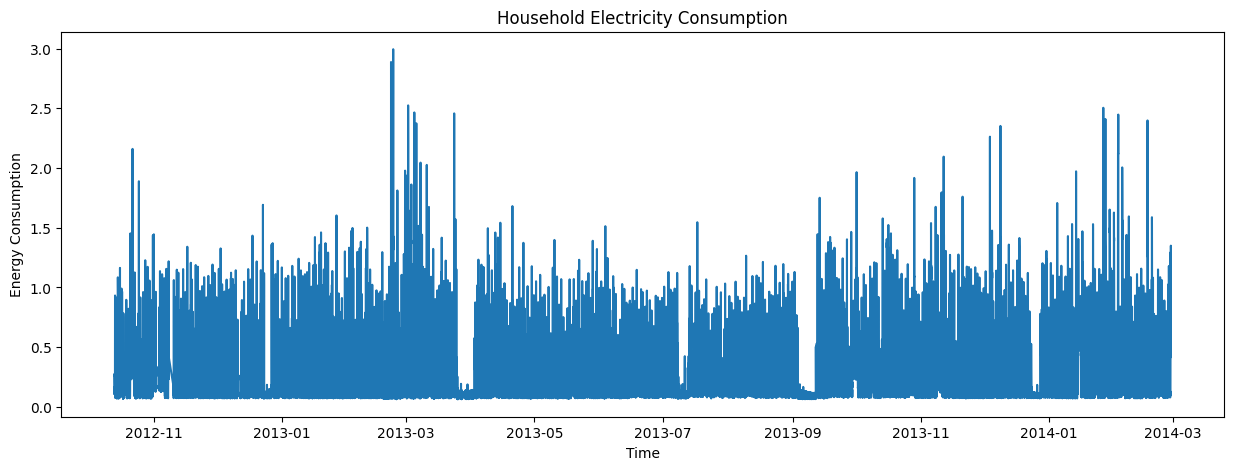

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    df["timestamp"],
    df["energy"]
)

plt.xlabel("Time")
plt.ylabel("Energy Consumption")
plt.title("Household Electricity Consumption")

plt.show()

# Look at only one week

The complete dataset can be difficult to visualize.

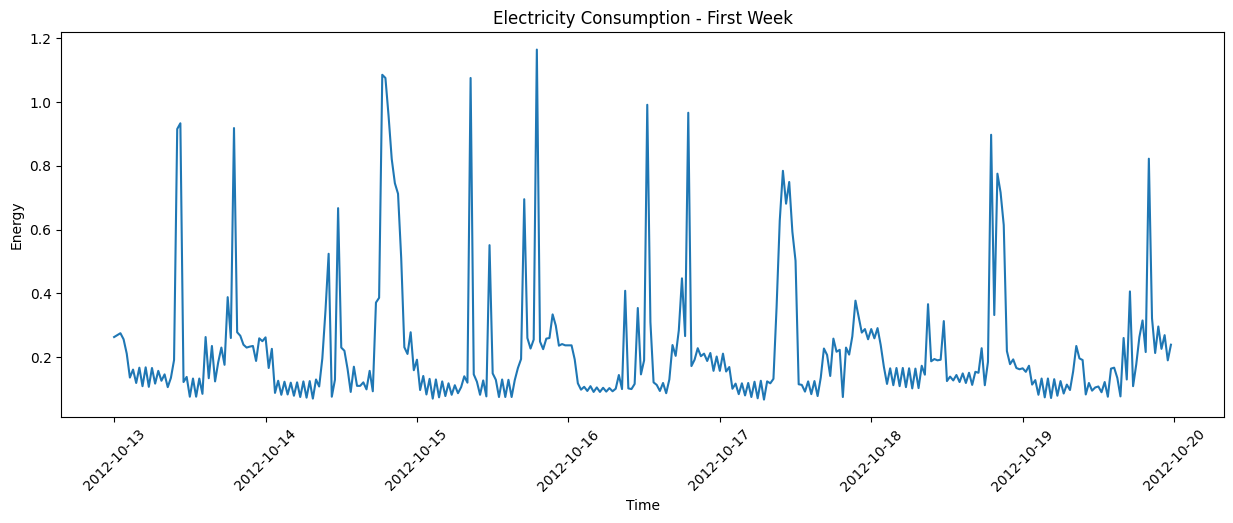

In [45]:
one_week = df.iloc[:336]

plt.figure(figsize=(15, 5))

plt.plot(
    one_week["timestamp"],
    one_week["energy"]
)

plt.xlabel("Time")
plt.ylabel("Energy")
plt.title("Electricity Consumption - First Week")

plt.xticks(rotation=45)
plt.show()

# Weather

In [46]:
import pandas as pd
import numpy as np
import os

# Reload weather from original file
weather = pd.read_csv(
    os.path.join(DATA_DIR, "weather_hourly_darksky.csv")
)

print(weather.dtypes)
display(weather.head())

visibility             float64
windBearing              int64
temperature            float64
time                    object
dewPoint               float64
pressure               float64
apparentTemperature    float64
windSpeed              float64
precipType              object
icon                    object
humidity               float64
summary                 object
dtype: object


,visibility,windBearing,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,5.97,104,10.24,2011-11-11 00:00:00,8.86,1016.76,10.24,2.77,rain,partly-cloudy-night,0.91,Partly Cloudy
1,4.88,99,9.76,2011-11-11 01:00:00,8.83,1016.63,8.24,2.95,rain,partly-cloudy-night,0.94,Partly Cloudy
2,3.70,98,9.46,2011-11-11 02:00:00,8.79,1016.36,7.76,3.17,rain,partly-cloudy-night,0.96,Partly Cloudy
3,3.12,99,9.23,2011-11-11 03:00:00,8.63,1016.28,7.44,3.25,rain,fog,0.96,Foggy
4,1.85,111,9.26,2011-11-11 04:00:00,9.21,1015.98,7.24,3.70,rain,fog,1.00,Foggy


In [47]:
weather.columns.tolist()

['visibility',
 'windBearing',
 'temperature',
 'time',
 'dewPoint',
 'pressure',
 'apparentTemperature',
 'windSpeed',
 'precipType',
 'icon',
 'humidity',
 'summary']

In [48]:
if pd.api.types.is_numeric_dtype(weather["time"]):
    weather["time"] = pd.to_datetime(
        weather["time"],
        unit="s",
        utc=True
    ).dt.tz_convert("Europe/London").dt.tz_localize(None)
else:
    weather["time"] = pd.to_datetime(
        weather["time"],
        errors="coerce"
    )

weather = weather.sort_values("time").reset_index(drop=True)

print(weather["time"].min())
print(weather["time"].max())

display(weather.head())

2011-11-01 00:00:00
2014-03-31 22:00:00


,visibility,windBearing,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,13.63,160,13.49,2011-11-01 00:00:00,11.48,1008.14,13.49,3.11,rain,clear-night,0.88,Clear
1,13.26,154,12.73,2011-11-01 01:00:00,11.58,1007.88,12.73,3.08,rain,partly-cloudy-night,0.93,Partly Cloudy
2,12.94,161,13.65,2011-11-01 02:00:00,12.14,1007.09,13.65,3.71,rain,clear-night,0.91,Clear
3,12.99,170,14.13,2011-11-01 03:00:00,12.24,1006.50,14.13,3.95,rain,partly-cloudy-night,0.88,Partly Cloudy
4,12.92,180,14.17,2011-11-01 04:00:00,12.59,1006.14,14.17,3.97,rain,partly-cloudy-night,0.90,Partly Cloudy


In [49]:
weather['precipType'].unique()

array(['rain', 'snow'], dtype=object)

In [50]:
print(weather.dtypes)

visibility                    float64
windBearing                     int64
temperature                   float64
time                   datetime64[ns]
dewPoint                      float64
pressure                      float64
apparentTemperature           float64
windSpeed                     float64
precipType                     object
icon                           object
humidity                      float64
summary                        object
dtype: object


# Select useful weather columns

We don't need every weather column initially.

In [51]:
weather_features = [
    "time",
    "temperature",
    "humidity",
    "pressure",
    "windSpeed",
    "visibility",
    "apparentTemperature",
    "dewPoint",
    "windBearing"
]

weather_model = weather[weather_features].copy()

display(weather_model.head())

,time,temperature,humidity,pressure,windSpeed,visibility,apparentTemperature,dewPoint,windBearing
0,2011-11-01 00:00:00,13.49,0.88,1008.14,3.11,13.63,13.49,11.48,160
1,2011-11-01 01:00:00,12.73,0.93,1007.88,3.08,13.26,12.73,11.58,154
2,2011-11-01 02:00:00,13.65,0.91,1007.09,3.71,12.94,13.65,12.14,161
3,2011-11-01 03:00:00,14.13,0.88,1006.50,3.95,12.99,14.13,12.24,170
4,2011-11-01 04:00:00,14.17,0.90,1006.14,3.97,12.92,14.17,12.59,180


In [52]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values("timestamp").reset_index(drop=True)

print(df["timestamp"].min())
print(df["timestamp"].max())

2012-10-13 00:00:00
2014-02-27 23:30:00


# Merge electricity + weather 🌦️

Because electricity is every 30 minutes while weather is hourly, don't use a normal merge().

In [53]:
df_weather = pd.merge_asof(
    df.sort_values("timestamp"),
    weather_model.sort_values("time"),
    left_on="timestamp",
    right_on="time",
    direction="nearest",
    tolerance=pd.Timedelta("45min")
)

In [54]:
df_weather = df_weather.drop(
    columns=["time"]
)

In [55]:
display(df_weather.head())

,LCLid,timestamp,energy,temperature,humidity,pressure,windSpeed,visibility,apparentTemperature,dewPoint,windBearing
0,MAC000002,2012-10-13 00:00:00,0.263,8.78,0.84,1007.70,2.28,13.08,7.55,6.28,186.0
1,MAC000002,2012-10-13 00:30:00,0.269,8.78,0.84,1007.70,2.28,13.08,7.55,6.28,186.0
2,MAC000002,2012-10-13 01:00:00,0.275,8.27,0.87,1007.36,1.81,13.42,7.34,6.21,188.0
3,MAC000002,2012-10-13 01:30:00,0.256,8.27,0.87,1007.36,1.81,13.42,7.34,6.21,188.0
4,MAC000002,2012-10-13 02:00:00,0.211,7.87,0.89,1006.73,1.95,13.94,6.75,6.22,190.0


# Holiday

In [56]:
holiday_path = os.path.join(
    DATA_DIR,
    "uk_bank_holidays.csv"
)

holidays = pd.read_csv(holiday_path)

print("Shape:", holidays.shape)
print("\nColumns:")
print(holidays.columns.tolist())

display(holidays.head())

Shape: (25, 2)

Columns:
['Bank holidays', 'Type']


,Bank holidays,Type
0,2012-12-26,Boxing Day
1,2012-12-25,Christmas Day
2,2012-08-27,Summer bank holiday
3,2012-05-06,Queen?s Diamond Jubilee (extra bank holiday)
4,2012-04-06,Spring bank holiday (substitute day)


In [57]:
display(df.head())
print(df.columns.tolist())

,LCLid,timestamp,energy
0,MAC000002,2012-10-13 00:00:00,0.263
1,MAC000002,2012-10-13 00:30:00,0.269
2,MAC000002,2012-10-13 01:00:00,0.275
3,MAC000002,2012-10-13 01:30:00,0.256
4,MAC000002,2012-10-13 02:00:00,0.211


['LCLid', 'timestamp', 'energy']


# Add time features

In [58]:
df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute

df["day_of_week"] = df["timestamp"].dt.dayofweek

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df["month"] = df["timestamp"].dt.month

df["day_of_month"] = df["timestamp"].dt.day

In [59]:
display(df.head())


,LCLid,timestamp,energy,hour,minute,day_of_week,is_weekend,month,day_of_month
0,MAC000002,2012-10-13 00:00:00,0.263,0,0,5,1,10,13
1,MAC000002,2012-10-13 00:30:00,0.269,0,30,5,1,10,13
2,MAC000002,2012-10-13 01:00:00,0.275,1,0,5,1,10,13
3,MAC000002,2012-10-13 01:30:00,0.256,1,30,5,1,10,13
4,MAC000002,2012-10-13 02:00:00,0.211,2,0,5,1,10,13


In [60]:
print(df.columns.tolist())

['LCLid', 'timestamp', 'energy', 'hour', 'minute', 'day_of_week', 'is_weekend', 'month', 'day_of_month']


# Add lag features

In [61]:
df["lag_1"] = df["energy"].shift(1)
df["lag_2"] = df["energy"].shift(2)
df["lag_48"] = df["energy"].shift(48)
df["lag_336"] = df["energy"].shift(336)

30 minutes = 1 observation

1 hour = 2 observations

1 day = 48 observations

7 days = 336 observations

In [62]:
display(
    df[
        [
            "timestamp",
            "energy",
            "lag_1",
            "lag_2",
            "lag_48",
            "lag_336"
        ]
    ].head(350)
)

,timestamp,energy,lag_1,lag_2,lag_48,lag_336
0,2012-10-13 00:00:00,0.263,NaN,NaN,NaN,NaN
1,2012-10-13 00:30:00,0.269,0.263,NaN,NaN,NaN
2,2012-10-13 01:00:00,0.275,0.269,0.263,NaN,NaN
3,2012-10-13 01:30:00,0.256,0.275,0.269,NaN,NaN
4,2012-10-13 02:00:00,0.211,0.256,0.275,NaN,NaN
...,...,...,...,...,...,...
345,2012-10-20 04:30:00,0.118,0.097,0.120,0.072,0.109
346,2012-10-20 05:00:00,0.095,0.118,0.097,0.131,0.168
347,2012-10-20 05:30:00,0.119,0.095,0.118,0.079,0.107
348,2012-10-20 06:00:00,0.089,0.119,0.095,0.125,0.166


# Add rolling features

These can help the model understand the recent consumption trend.

In [63]:
df["rolling_24h"] = (
    df["energy"]
    .rolling(48)
    .mean()
)

df["rolling_7d"] = (
    df["energy"]
    .rolling(336)
    .mean()
)

In [64]:
df = df.dropna().reset_index(drop=True)

In [65]:
print("Shape:", df.shape)
display(df.head())

Shape: (23567, 15)


,LCLid,timestamp,energy,hour,minute,day_of_week,is_weekend,month,day_of_month,lag_1,lag_2,lag_48,lag_336,rolling_24h,rolling_7d
0,MAC000002,2012-10-20 00:00:00,0.200,0,0,5,1,10,20,0.239,0.190,0.165,0.263,0.176375,0.221250
1,MAC000002,2012-10-20 00:30:00,0.229,0,30,5,1,10,20,0.200,0.239,0.154,0.269,0.177937,0.221131
2,MAC000002,2012-10-20 01:00:00,0.192,1,0,5,1,10,20,0.229,0.200,0.173,0.275,0.178333,0.220884
3,MAC000002,2012-10-20 01:30:00,0.217,1,30,5,1,10,20,0.192,0.229,0.114,0.256,0.180479,0.220768
4,MAC000002,2012-10-20 02:00:00,0.180,2,0,5,1,10,20,0.217,0.192,0.128,0.211,0.181562,0.220676


# Prepare weather timestamp

In [66]:
weather["time"] = pd.to_datetime(weather["time"])

weather = weather.sort_values("time").reset_index(drop=True)

In [67]:
print(weather.dtypes)
display(weather.head())

visibility                    float64
windBearing                     int64
temperature                   float64
time                   datetime64[ns]
dewPoint                      float64
pressure                      float64
apparentTemperature           float64
windSpeed                     float64
precipType                     object
icon                           object
humidity                      float64
summary                        object
dtype: object


,visibility,windBearing,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,13.63,160,13.49,2011-11-01 00:00:00,11.48,1008.14,13.49,3.11,rain,clear-night,0.88,Clear
1,13.26,154,12.73,2011-11-01 01:00:00,11.58,1007.88,12.73,3.08,rain,partly-cloudy-night,0.93,Partly Cloudy
2,12.94,161,13.65,2011-11-01 02:00:00,12.14,1007.09,13.65,3.71,rain,clear-night,0.91,Clear
3,12.99,170,14.13,2011-11-01 03:00:00,12.24,1006.50,14.13,3.95,rain,partly-cloudy-night,0.88,Partly Cloudy
4,12.92,180,14.17,2011-11-01 04:00:00,12.59,1006.14,14.17,3.97,rain,partly-cloudy-night,0.90,Partly Cloudy


# Merge electricity + weather

Because:

Electricity → every 30 minutes

Weather → every 1 hour

we use merge_asof() rather than a normal merge().

In [72]:
import pandas as pd
import numpy as np

# Work on copies
df = df.copy()
weather = weather.copy()
holidays = holidays.copy()

# Convert timestamps
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
weather["time"] = pd.to_datetime(weather["time"], errors="coerce")

# Remove invalid timestamps
df = df.dropna(subset=["timestamp"])
weather = weather.dropna(subset=["time"])

# Sort both datasets
df = df.sort_values("timestamp").reset_index(drop=True)
weather = weather.sort_values("time").reset_index(drop=True)

# Merge each electricity reading with the latest available weather reading
df_weather = pd.merge_asof(
    df,
    weather,
    left_on="timestamp",
    right_on="time",
    direction="backward",
    tolerance=pd.Timedelta("2 hours")
)

# Inspect the merged data
display(df_weather.head())

print("Merged shape:", df_weather.shape)
print("Columns:", df_weather.columns.tolist())
print("Missing weather values:")
print(df_weather[weather.columns.difference(["time"])].isna().sum())

,LCLid,timestamp,energy,hour,minute,day_of_week,is_weekend,month,day_of_month,lag_1,...,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,MAC000002,2012-10-20 00:00:00,0.200,0,0,5,1,10,20,0.239,...,11.91,2012-10-20 00:00:00,11.00,1010.75,11.91,2.65,rain,partly-cloudy-night,0.94,Mostly Cloudy
1,MAC000002,2012-10-20 00:30:00,0.229,0,30,5,1,10,20,0.200,...,11.91,2012-10-20 00:00:00,11.00,1010.75,11.91,2.65,rain,partly-cloudy-night,0.94,Mostly Cloudy
2,MAC000002,2012-10-20 01:00:00,0.192,1,0,5,1,10,20,0.229,...,11.45,2012-10-20 01:00:00,10.88,1011.16,11.45,2.29,rain,partly-cloudy-night,0.96,Mostly Cloudy
3,MAC000002,2012-10-20 01:30:00,0.217,1,30,5,1,10,20,0.192,...,11.45,2012-10-20 01:00:00,10.88,1011.16,11.45,2.29,rain,partly-cloudy-night,0.96,Mostly Cloudy
4,MAC000002,2012-10-20 02:00:00,0.180,2,0,5,1,10,20,0.217,...,10.97,2012-10-20 02:00:00,10.38,1012.00,10.97,2.47,rain,partly-cloudy-night,0.96,Mostly Cloudy


Merged shape: (23567, 27)
Columns: ['LCLid', 'timestamp', 'energy', 'hour', 'minute', 'day_of_week', 'is_weekend', 'month', 'day_of_month', 'lag_1', 'lag_2', 'lag_48', 'lag_336', 'rolling_24h', 'rolling_7d', 'visibility', 'windBearing', 'temperature', 'time', 'dewPoint', 'pressure', 'apparentTemperature', 'windSpeed', 'precipType', 'icon', 'humidity', 'summary']
Missing weather values:
apparentTemperature     1
dewPoint                1
humidity                1
icon                    1
precipType              1
pressure               21
summary                 1
temperature             1
visibility              1
windBearing             1
windSpeed               1
dtype: int64


# Clean the merged data

In [73]:
# Remove duplicate electricity timestamps for the same household, if applicable
if "LCLid" in df_weather.columns:
    df_weather = df_weather.drop_duplicates(
        subset=["LCLid", "timestamp"]
    )
else:
    df_weather = df_weather.drop_duplicates(
        subset=["timestamp"]
    )

df_weather = df_weather.sort_values("timestamp").reset_index(drop=True)

# Inspect missing values
missing = df_weather.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

# Convert weather fields to numeric where possible
weather_numeric_candidates = [
    "temperature",
    "apparentTemperature",
    "humidity",
    "windSpeed",
    "visibility",
    "pressure",
    "dewPoint",
    "windBearing"
]

for col in weather_numeric_candidates:
    if col in df_weather.columns:
        df_weather[col] = pd.to_numeric(
            df_weather[col], errors="coerce"
        )

# Fill weather gaps using nearby observations in time
weather_cols = [
    col for col in weather_numeric_candidates
    if col in df_weather.columns
]

df_weather[weather_cols] = (
    df_weather[weather_cols]
    .interpolate(limit_direction="both")
)

display(df_weather.head())
print("Shape after cleaning:", df_weather.shape)

,missing_count
pressure,21
icon,1
humidity,1
visibility,1
dewPoint,1
apparentTemperature,1
windSpeed,1
temperature,1
windBearing,1
time,1


,LCLid,timestamp,energy,hour,minute,day_of_week,is_weekend,month,day_of_month,lag_1,...,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,MAC000002,2012-10-20 00:00:00,0.200,0,0,5,1,10,20,0.239,...,11.91,2012-10-20 00:00:00,11.00,1010.75,11.91,2.65,rain,partly-cloudy-night,0.94,Mostly Cloudy
1,MAC000002,2012-10-20 00:30:00,0.229,0,30,5,1,10,20,0.200,...,11.91,2012-10-20 00:00:00,11.00,1010.75,11.91,2.65,rain,partly-cloudy-night,0.94,Mostly Cloudy
2,MAC000002,2012-10-20 01:00:00,0.192,1,0,5,1,10,20,0.229,...,11.45,2012-10-20 01:00:00,10.88,1011.16,11.45,2.29,rain,partly-cloudy-night,0.96,Mostly Cloudy
3,MAC000002,2012-10-20 01:30:00,0.217,1,30,5,1,10,20,0.192,...,11.45,2012-10-20 01:00:00,10.88,1011.16,11.45,2.29,rain,partly-cloudy-night,0.96,Mostly Cloudy
4,MAC000002,2012-10-20 02:00:00,0.180,2,0,5,1,10,20,0.217,...,10.97,2012-10-20 02:00:00,10.38,1012.00,10.97,2.47,rain,partly-cloudy-night,0.96,Mostly Cloudy


Shape after cleaning: (23567, 27)


In [69]:
display(df_weather.head())

,LCLid,timestamp,energy,hour,minute,day_of_week,is_weekend,month,day_of_month,lag_1,...,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,MAC000002,2012-10-20 00:00:00,0.200,0,0,5,1,10,20,0.239,...,11.91,2012-10-20 00:00:00,11.00,1010.75,11.91,2.65,rain,partly-cloudy-night,0.94,Mostly Cloudy
1,MAC000002,2012-10-20 00:30:00,0.229,0,30,5,1,10,20,0.200,...,11.91,2012-10-20 00:00:00,11.00,1010.75,11.91,2.65,rain,partly-cloudy-night,0.94,Mostly Cloudy
2,MAC000002,2012-10-20 01:00:00,0.192,1,0,5,1,10,20,0.229,...,11.45,2012-10-20 01:00:00,10.88,1011.16,11.45,2.29,rain,partly-cloudy-night,0.96,Mostly Cloudy
3,MAC000002,2012-10-20 01:30:00,0.217,1,30,5,1,10,20,0.192,...,11.45,2012-10-20 01:00:00,10.88,1011.16,11.45,2.29,rain,partly-cloudy-night,0.96,Mostly Cloudy
4,MAC000002,2012-10-20 02:00:00,0.180,2,0,5,1,10,20,0.217,...,10.97,2012-10-20 02:00:00,10.38,1012.00,10.97,2.47,rain,partly-cloudy-night,0.96,Mostly Cloudy


In [70]:
print(df_weather.shape)
print(df_weather.columns.tolist())

(23567, 27)
['LCLid', 'timestamp', 'energy', 'hour', 'minute', 'day_of_week', 'is_weekend', 'month', 'day_of_month', 'lag_1', 'lag_2', 'lag_48', 'lag_336', 'rolling_24h', 'rolling_7d', 'visibility', 'windBearing', 'temperature', 'time', 'dewPoint', 'pressure', 'apparentTemperature', 'windSpeed', 'precipType', 'icon', 'humidity', 'summary']


In [71]:
print("WEATHER COLUMNS:")
print(weather.columns.tolist())

print("\nHOLIDAY COLUMNS:")
print(holidays.columns.tolist())

WEATHER COLUMNS:
['visibility', 'windBearing', 'temperature', 'time', 'dewPoint', 'pressure', 'apparentTemperature', 'windSpeed', 'precipType', 'icon', 'humidity', 'summary']

HOLIDAY COLUMNS:
['Bank holidays', 'Type']


# # Feature Engineering for Smart Meter Energy Consumption Forecasting Using LSTM

## 1. Introduction

Feature engineering is an important step in time-series forecasting. It involves creating and selecting meaningful features from raw data to improve the performance of a machine learning or deep learning model.

In this project, we use the **Smart Meters in London dataset** to analyze household electricity consumption and predict future energy usage using a Long Short-Term Memory (LSTM) neural network.

The dataset combines three major types of information:

- **Smart meter data:** Historical electricity consumption for individual households.
- **Time-based features:** Hour, minute, day of the week, month, and other calendar information.
- **Weather features:** Temperature, humidity, wind speed, atmospheric pressure, and weather conditions.

Combining these features helps the model learn temporal patterns and understand how time and weather conditions may influence electricity consumption.

## 2. Understanding the Dataset Columns

### 2.1. LCLid

**Definition:** `LCLid` is the unique identifier assigned to a household or smart meter.

**Example:** `MAC000002`

**Importance:** It allows us to distinguish between households and organize their electricity consumption records separately.

For time-series forecasting, observations must be sorted by both `LCLid` and `timestamp`. Lag features must be calculated separately for each household to prevent information from one household from entering another household's historical sequence.

### 2.2. Timestamp

**Definition:** `timestamp` represents the date and time when an electricity consumption reading was recorded.

**Example:** `2012-10-20 00:30:00`

**Importance:** It establishes the chronological order of observations and allows us to extract useful time-based features.

The timestamp is essential for:
- Sorting energy readings chronologically.
- Identifying hourly, daily, weekly, and seasonal consumption patterns.
- Creating lag features.
- Splitting the dataset into training, validation, and testing periods.

### 2.3. Energy

**Definition:** `energy` represents the electricity consumed during the recorded interval, generally measured in kilowatt-hours (kWh).

**Example:** `0.229`

**Importance:** This is the primary target variable for our forecasting model.

The LSTM model learns patterns from historical energy consumption and uses them to predict future consumption.

For example:

Historical energy readings → LSTM model → Predicted future energy consumption

The precise forecasting target depends on the prediction horizon. In this project, we can predict the next 30-minute consumption value using historical readings and relevant features.

## 3. Time-Based Feature Engineering

Time-based features help the model identify recurring consumption patterns associated with different times and days.

### 3.1. Hour

**Definition:** `hour` represents the hour of the day, ranging from 0 to 23.

Examples:
- 0: Midnight
- 6: 6 AM
- 12: Noon
- 18: 6 PM
- 23: 11 PM

**Importance:** Electricity consumption can vary throughout the day. For example, consumption may increase in the morning or evening when household appliances are used more frequently.

### 3.2. Minute

**Definition:** `minute` represents the minute within an hour.

For half-hourly readings, the usual values are 0 and 30.

**Importance:** This feature helps distinguish between readings recorded at different points within an hour.

### 3.3. Day of the Week

**Definition:** `day_of_week` identifies the day of the week, usually encoded from 0 to 6.

- 0: Monday
- 1: Tuesday
- 2: Wednesday
- 3: Thursday
- 4: Friday
- 5: Saturday
- 6: Sunday

**Importance:** Household electricity consumption may differ between weekdays and weekends because of differences in work schedules, household activities, and appliance usage.

### 3.4. Is Weekend

**Definition:** `is_weekend` is a binary feature indicating whether a date falls on Saturday or Sunday.

- 0: Weekday
- 1: Weekend

**Importance:** This feature provides an explicit indicator of weekend behavior without requiring the model to infer it from the day number alone.

### 3.5. Month

**Definition:** `month` represents the month of the year, ranging from 1 to 12.

**Importance:** Electricity consumption can change seasonally because of differences in temperature, daylight hours, heating requirements, and household activities.

For example, colder months may have higher heating-related consumption in some households.

### 3.6. Day of the Month

**Definition:** `day_of_month` represents the day within a month, ranging from 1 to 31.

**Importance:** It can help identify recurring monthly patterns. However, its usefulness should be evaluated because the day number does not represent a continuous sequence across month boundaries.

## 4. Lag Features

Lag features represent historical values of the target variable. They are particularly useful in time-series forecasting because recent and recurring consumption patterns can help predict future demand.

### 4.1. Lag 1

**Definition:** `lag_1` represents the previous energy reading for the same household.

For regularly spaced half-hourly data, it corresponds to the reading from 30 minutes earlier.

**Example:**

| Timestamp | Energy | Lag 1 |
|---|---:|---:|
| 00:00 | 0.200 | Missing |
| 00:30 | 0.229 | 0.200 |
| 01:00 | 0.192 | 0.229 |

**Importance:** The previous reading provides information about recent consumption behavior.

### 4.2. Lag 2

**Definition:** `lag_2` represents the energy consumption recorded two time steps earlier.

For half-hourly data, it corresponds to one hour earlier.

### 4.3. Lag 3

**Definition:** `lag_3` represents the energy consumption recorded three time steps earlier.

For half-hourly data, it corresponds to 90 minutes earlier.

### 4.4. Lag 48

**Definition:** `lag_48` represents the energy consumption recorded 48 half-hourly time steps earlier.

This corresponds to 24 hours earlier when readings are complete and regularly spaced.

**Importance:** It helps the model identify daily consumption patterns, such as differences between morning, afternoon, and evening usage.

### 4.5. Lag 336

**Definition:** `lag_336` represents the energy consumption recorded 336 half-hourly time steps earlier.

This corresponds to seven days earlier when the time series is regularly spaced.

**Importance:** It can help identify weekly patterns by comparing consumption at approximately the same time on different days of the week.

**Important:** Lag features must be calculated separately for each household after sorting by timestamp. Missing time intervals must be checked because a shift of 48 rows does not necessarily equal 24 hours if readings are missing.

## 5. Weather Features

Weather conditions can influence household electricity demand. Including weather information may help the model explain consumption changes that cannot be explained by time features alone.

### 5.1. Temperature

**Definition:** `temperature` represents the measured air temperature, generally in degrees Celsius.

**Importance:** Temperature may affect electricity consumption through heating, fans, and cooling appliances.

For example, electricity demand may increase during cold weather if households use electric heating.

### 5.2. Dew Point

**Definition:** `dewPoint` is the temperature at which air becomes saturated with water vapor under the relevant conditions.

**Importance:** It provides information about atmospheric moisture and can help describe weather conditions alongside temperature and humidity.

### 5.3. Pressure

**Definition:** `pressure` represents atmospheric pressure.

**Importance:** Atmospheric pressure can provide additional information about weather conditions. Its contribution to household energy prediction may be smaller than that of temperature, so its usefulness should be evaluated during model development.

### 5.4. Apparent Temperature

**Definition:** `apparentTemperature` represents how warm or cold the weather feels to a person.

**Importance:** Perceived temperature can influence heating or cooling behavior. It may also be correlated with the actual temperature, so redundant information should be considered during feature selection.

### 5.5. Wind Speed

**Definition:** `windSpeed` represents the speed of the wind, generally measured in metres per second in this dataset.

**Importance:** Wind can influence perceived temperature and heating requirements. It provides additional context about environmental conditions.

### 5.6. Humidity

**Definition:** `humidity` represents relative humidity. In this dataset, values such as 0.94 generally represent 94% relative humidity.

**Importance:** Humidity describes moisture in the air and may influence perceived comfort and the use of household appliances.

## 6. Categorical Weather Features

Some weather columns contain text rather than numerical values. These features must be encoded before they can be used as inputs to a standard LSTM model.

### 6.1. PrecipType

**Definition:** `precipType` describes the type of precipitation, such as rain or snow.

**Importance:** Precipitation can provide additional context about weather conditions that may indirectly influence household activities and electricity consumption.

**Preprocessing:** Missing values should be investigated, and categorical values can be encoded using one-hot encoding.

### 6.2. Icon

**Definition:** `icon` contains a textual weather-condition category, such as `partly-cloudy-night`.

**Importance:** It provides a categorical representation of weather conditions.

**Preprocessing:** One-hot encoding or another suitable categorical encoding method can convert the feature into numerical inputs.

### 6.3. Summary

**Definition:** `summary` provides a human-readable description of the weather, such as `Mostly Cloudy`.

**Importance:** It provides additional descriptive information about the observed weather conditions.

**Preprocessing:** The column can be encoded if it provides useful information. However, it may overlap with the information already contained in `icon`, so both features should be evaluated rather than automatically retained.

## 7. Understanding the Weather Timestamp

### Time

**Definition:** `time` represents the date and time associated with a weather observation.

The smart meter data may be recorded every 30 minutes, while weather data may be recorded hourly. Consequently, two consecutive smart meter readings may share the same weather observation.

**Importance:** The weather timestamp helps align weather measurements with the corresponding smart meter readings.

During preprocessing, the weather dataset should be joined to the smart meter dataset using an appropriate timestamp-matching strategy. The raw weather timestamp is generally not required as a separate model input when `timestamp` already represents the forecasting timeline.

## 8. Why Combine Smart Meter, Time, and Weather Features?

Combining these features allows the LSTM model to learn from multiple sources of information.

- **Historical energy readings** provide information about previous consumption.
- **Time-based features** represent daily, weekly, and seasonal patterns.
- **Lag features** provide explicit historical reference points.
- **Weather features** describe environmental conditions that may influence energy demand.

For example, electricity consumption at 6 PM may depend on the household's recent consumption, the day of the week, the season, and the temperature.

The model can learn these relationships from historical data rather than relying on manually defined rules.

## 9. Data Preprocessing Before LSTM Training

Before training the model, the following preprocessing steps are necessary:

1. Convert `timestamp` and weather timestamps to datetime format.
2. Sort observations by household and timestamp.
3. Remove duplicate household-timestamp records after checking their validity.
4. Generate time-based and lag features correctly.
5. Investigate missing energy and weather values.
6. Encode categorical features such as `precipType`, `icon`, and `summary`.
7. Scale numerical input features using a scaler fitted only on the training data.
8. Split the data chronologically into training, validation, and test sets.
9. Construct sequential input windows for the LSTM.
10. Evaluate the predictions using metrics such as MAE, RMSE, and R².

Missing lag values at the beginning of a household's time series are expected because earlier observations do not exist. These values should be handled appropriately before training.

## 10. Preventing Data Leakage

Data leakage occurs when information unavailable at prediction time is used to train or evaluate a forecasting model.

To avoid leakage:

- Calculate lag features using past observations only.
- Never use future energy consumption as an input when predicting it.
- Fit scalers and encoders using training data only.
- Preserve chronological order when creating training, validation, and test sets.
- Ensure weather features are available at the forecast origin. If actual future weather observations would not yet be available in deployment, use weather forecasts or omit those future weather inputs.

These steps help produce realistic and reliable forecasting results.

## 11. Conclusion

Feature engineering transforms raw smart meter and weather data into meaningful inputs for time-series forecasting.

In this project, the `energy` column is the target variable, `timestamp` establishes the chronological sequence, time-based features describe calendar patterns, lag features represent historical consumption, and weather features provide environmental context.

After appropriate preprocessing and sequence construction, these features can be supplied to an LSTM model to learn temporal patterns and predict future household electricity consumption.

The final performance depends on data quality, feature selection, forecasting horizon, sequence length, model architecture, and the evaluation strategy.


# Add holiday information

In [74]:
holidays = holidays.copy()

holidays["holiday_date"] = pd.to_datetime(
    holidays["Bank holidays"], errors="coerce"
).dt.normalize()

holiday_dates = set(
    holidays["holiday_date"].dropna().unique()
)

df_weather["date"] = df_weather["timestamp"].dt.normalize()

df_weather["is_holiday"] = (
    df_weather["date"].isin(holiday_dates).astype("int8")
)

print("Holiday feature added.")
display(df_weather[["timestamp", "date", "is_holiday"]].head())

Holiday feature added.


,timestamp,date,is_holiday
0,2012-10-20 00:00:00,2012-10-20,0
1,2012-10-20 00:30:00,2012-10-20,0
2,2012-10-20 01:00:00,2012-10-20,0
3,2012-10-20 01:30:00,2012-10-20,0
4,2012-10-20 02:00:00,2012-10-20,0


# Add time-based features

In [75]:
df_weather["hour"] = df_weather["timestamp"].dt.hour
df_weather["day_of_week"] = df_weather["timestamp"].dt.dayofweek
df_weather["month"] = df_weather["timestamp"].dt.month
df_weather["is_weekend"] = (
    df_weather["day_of_week"] >= 5
).astype("int8")

# Cyclical encoding: 23:00 and 00:00 are close in time
df_weather["hour_sin"] = np.sin(
    2 * np.pi * df_weather["hour"] / 24
)
df_weather["hour_cos"] = np.cos(
    2 * np.pi * df_weather["hour"] / 24
)

df_weather["day_sin"] = np.sin(
    2 * np.pi * df_weather["day_of_week"] / 7
)
df_weather["day_cos"] = np.cos(
    2 * np.pi * df_weather["day_of_week"] / 7
)

display(df_weather.head())

,LCLid,timestamp,energy,hour,minute,day_of_week,is_weekend,month,day_of_month,lag_1,...,precipType,icon,humidity,summary,date,is_holiday,hour_sin,hour_cos,day_sin,day_cos
0,MAC000002,2012-10-20 00:00:00,0.200,0,0,5,1,10,20,0.239,...,rain,partly-cloudy-night,0.94,Mostly Cloudy,2012-10-20,0,0.000000,1.000000,-0.974928,-0.222521
1,MAC000002,2012-10-20 00:30:00,0.229,0,30,5,1,10,20,0.200,...,rain,partly-cloudy-night,0.94,Mostly Cloudy,2012-10-20,0,0.000000,1.000000,-0.974928,-0.222521
2,MAC000002,2012-10-20 01:00:00,0.192,1,0,5,1,10,20,0.229,...,rain,partly-cloudy-night,0.96,Mostly Cloudy,2012-10-20,0,0.258819,0.965926,-0.974928,-0.222521
3,MAC000002,2012-10-20 01:30:00,0.217,1,30,5,1,10,20,0.192,...,rain,partly-cloudy-night,0.96,Mostly Cloudy,2012-10-20,0,0.258819,0.965926,-0.974928,-0.222521
4,MAC000002,2012-10-20 02:00:00,0.180,2,0,5,1,10,20,0.217,...,rain,partly-cloudy-night,0.96,Mostly Cloudy,2012-10-20,0,0.500000,0.866025,-0.974928,-0.222521


# Select the household and target column
For your first LSTM model, let's predict the next half-hour's electricity consumption. If your data contains multiple households, we'll select one household to avoid mixing different households' sequences.

In [76]:
# Identify the target column
possible_targets = ["energy", "consumption", "energy_consumption"]

target_col = next(
    (col for col in possible_targets if col in df_weather.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Target column not found. Check df_weather.columns.tolist()"
    )

# Use one household for the first experiment
if "LCLid" in df_weather.columns:
    household_counts = df_weather["LCLid"].value_counts()

    if household_counts.empty:
        raise ValueError("No household IDs found.")

    household_id = household_counts.index[0]

    model_df = df_weather[
        df_weather["LCLid"] == household_id
    ].copy()

    print("Selected household:", household_id)
else:
    model_df = df_weather.copy()
    print("Using the available electricity time series.")

# Ensure chronological order
model_df = (
    model_df.sort_values("timestamp")
    .drop_duplicates(subset=["timestamp"])
    .reset_index(drop=True)
)

model_df[target_col] = pd.to_numeric(
    model_df[target_col], errors="coerce"
)

model_df = model_df.dropna(subset=[target_col])

print("Target column:", target_col)
print("Rows:", len(model_df))
display(model_df[["timestamp", target_col]].head())

Selected household: MAC000002
Target column: energy
Rows: 23567


,timestamp,energy
0,2012-10-20 00:00:00,0.200
1,2012-10-20 00:30:00,0.229
2,2012-10-20 01:00:00,0.192
3,2012-10-20 01:30:00,0.217
4,2012-10-20 02:00:00,0.180


# Select model features
We'll use electricity consumption, available numeric weather columns, and calendar features. The target is the future electricity reading.

In [77]:
calendar_features = [
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "is_weekend",
    "is_holiday"
]

weather_features = [
    col for col in [
        "temperature",
        "apparentTemperature",
        "humidity",
        "windSpeed",
        "visibility",
        "pressure",
        "dewPoint",
        "windBearing"
    ]
    if col in model_df.columns
]

feature_cols = list(dict.fromkeys(
    [target_col] + weather_features + calendar_features
))

# Make selected features numeric
for col in feature_cols:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

# Interpolate features within this household's time series
model_df[feature_cols] = (
    model_df[feature_cols]
    .interpolate(limit_direction="both")
)

model_df = model_df.dropna(
    subset=feature_cols
).reset_index(drop=True)

print("Features:", feature_cols)
print("Rows available for training:", len(model_df))

display(model_df[feature_cols].head())

Features: ['energy', 'temperature', 'apparentTemperature', 'humidity', 'windSpeed', 'visibility', 'pressure', 'dewPoint', 'windBearing', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'is_weekend', 'is_holiday']
Rows available for training: 23567


,energy,temperature,apparentTemperature,humidity,windSpeed,visibility,pressure,dewPoint,windBearing,hour_sin,hour_cos,day_sin,day_cos,is_weekend,is_holiday
0,0.200,11.91,11.91,0.94,2.65,4.63,1010.75,11.00,282.0,0.000000,1.000000,-0.974928,-0.222521,1,0
1,0.229,11.91,11.91,0.94,2.65,4.63,1010.75,11.00,282.0,0.000000,1.000000,-0.974928,-0.222521,1,0
2,0.192,11.45,11.45,0.96,2.29,5.58,1011.16,10.88,272.0,0.258819,0.965926,-0.974928,-0.222521,1,0
3,0.217,11.45,11.45,0.96,2.29,5.58,1011.16,10.88,272.0,0.258819,0.965926,-0.974928,-0.222521,1,0
4,0.180,10.97,10.97,0.96,2.47,4.46,1012.00,10.38,253.0,0.500000,0.866025,-0.974928,-0.222521,1,0


In [78]:
from sklearn.preprocessing import MinMaxScaler

if len(model_df) < 200:
    raise ValueError(
        "Too few observations for this experiment. "
        "Check the selected household and preprocessing."
    )

X_raw = model_df[feature_cols].to_numpy(dtype=np.float32)
y_raw = model_df[[target_col]].to_numpy(dtype=np.float32)

n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers using training data only
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(X_raw[:train_end])
target_scaler.fit(y_raw[:train_end])

X_scaled = feature_scaler.transform(X_raw).astype(np.float32)
y_scaled = target_scaler.transform(y_raw).astype(np.float32)

print("Training observations:", train_end)
print("Validation observations:", val_end - train_end)
print("Test observations:", n - val_end)

Training observations: 16496
Validation observations: 3535
Test observations: 3536


# reate sliding-window sequences
We'll use the previous 48 half-hour readings (24 hours) to predict the next half-hour's consumption.

In [79]:
LOOKBACK = 48

def create_sequences(X, y, lookback=48):
    X_seq, y_seq = [], []

    for i in range(lookback, len(X)):
        X_seq.append(X[i - lookback:i])
        y_seq.append(y[i])

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32)
    )

# Create sequences independently within each chronological partition.
# Validation and test inputs can use preceding historical observations,
# but their prediction targets remain inside their own partition.

X_train, y_train = create_sequences(
    X_scaled[:train_end],
    y_scaled[:train_end],
    LOOKBACK
)

X_val, y_val = create_sequences(
    X_scaled[train_end - LOOKBACK:val_end],
    y_scaled[train_end - LOOKBACK:val_end],
    LOOKBACK
)

X_test, y_test = create_sequences(
    X_scaled[val_end - LOOKBACK:],
    y_scaled[val_end - LOOKBACK:],
    LOOKBACK
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (16448, 48, 15)
y_train: (16448, 1)
X_val: (3535, 48, 15)
y_val: (3535, 1)
X_test: (3536, 48, 15)
y_test: (3536, 1)


# Build and train the LSTM model

In [80]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(LOOKBACK, len(feature_cols))),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

2026-10-16 00:21:31.991431: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    shuffle=False,
    verbose=1
)

Epoch 1/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - loss: 0.0067 - mae: 0.0499 - val_loss: 0.0074 - val_mae: 0.0553 - learning_rate: 0.0010
Epoch 2/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.0057 - mae: 0.0457 - val_loss: 0.0070 - val_mae: 0.0557 - learning_rate: 0.0010
Epoch 3/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - loss: 0.0055 - mae: 0.0450 - val_loss: 0.0067 - val_mae: 0.0531 - learning_rate: 0.0010
Epoch 4/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.0052 - mae: 0.0441 - val_loss: 0.0067 - val_mae: 0.0542 - learning_rate: 0.0010
Epoch 5/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.0050 - mae: 0.0432 - val_loss: 0.0063 - val_mae: 0.0517 - learning_rate: 0.0010
Epoch 6/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.0050 - mae: 0.0430 - val_loss: 0.0062 - val_mae: 0.0517 - learning_rate: 0.0010
Epoch 7/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.0048 - mae: 0.0424 - val_loss: 0.0062 - val_mae: 0.0520 - learning_rate:

# Evaluate on the test set

In [82]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict scaled values
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions and actual values to original units
y_pred = target_scaler.inverse_transform(y_pred_scaled).ravel()
y_actual = target_scaler.inverse_transform(y_test).ravel()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print(f"MAE:  {mae:.5f}")
print(f"RMSE: {rmse:.5f}")
print(f"R²:   {r2:.5f}")

MAE:  0.11914
RMSE: 0.19657
R²:   0.53382


# Plot training and validation loss

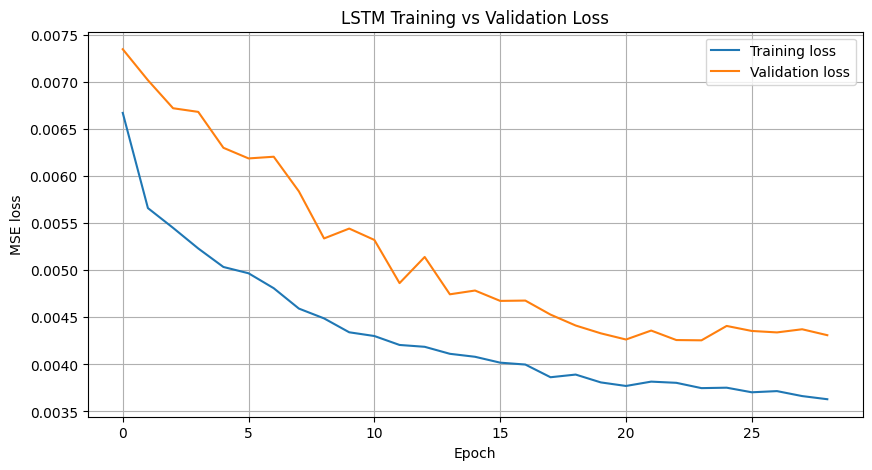

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Compare actual vs predicted consumption

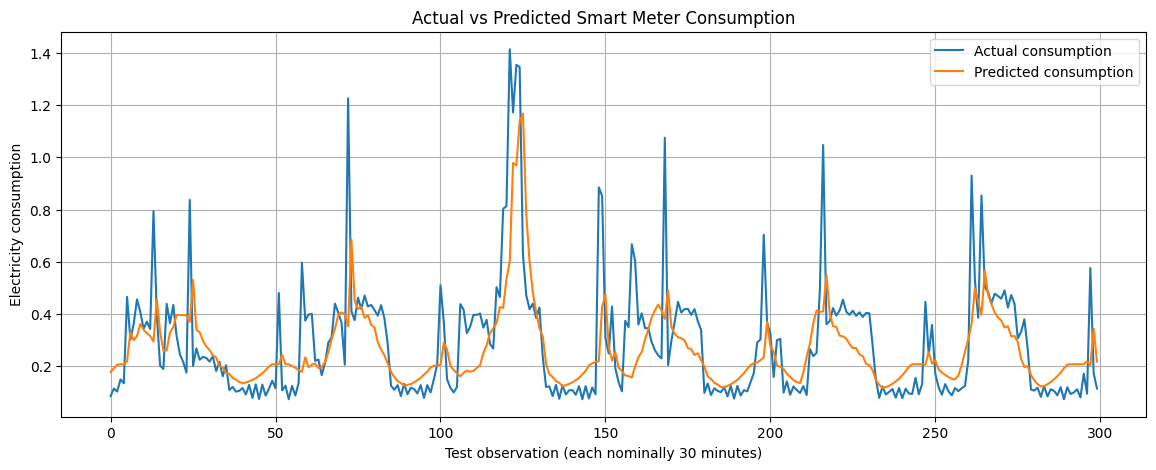

In [84]:
plt.figure(figsize=(14, 5))

plot_count = min(300, len(y_actual))

plt.plot(
    y_actual[:plot_count],
    label="Actual consumption"
)

plt.plot(
    y_pred[:plot_count],
    label="Predicted consumption"
)

plt.xlabel("Test observation (each nominally 30 minutes)")
plt.ylabel("Electricity consumption")
plt.title("Actual vs Predicted Smart Meter Consumption")
plt.legend()
plt.grid(True)
plt.show()

# Plot prediction errors

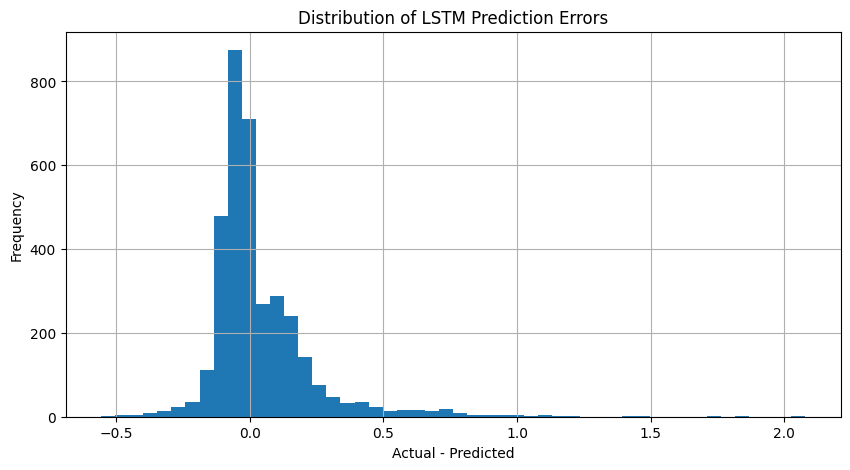

Mean error: 0.033807628
Median absolute error: 0.07551804


In [85]:
errors = y_actual - y_pred

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=50)

plt.xlabel("Actual - Predicted")
plt.ylabel("Frequency")
plt.title("Distribution of LSTM Prediction Errors")
plt.grid(True)
plt.show()

print("Mean error:", errors.mean())
print("Median absolute error:", np.median(np.abs(errors)))

# Make the next half-hour prediction
This predicts the next half-hour from the latest 48 available observations. It assumes your latest window is complete and has the same time interval as the training data.

In [86]:
latest_window = X_scaled[-LOOKBACK:]

latest_window = np.expand_dims(
    latest_window,
    axis=0
)

next_scaled = model.predict(
    latest_window,
    verbose=0
)

next_consumption = target_scaler.inverse_transform(
    next_scaled
)[0, 0]

last_timestamp = model_df["timestamp"].iloc[-1]
next_timestamp = last_timestamp + pd.Timedelta(minutes=30)

print("Last observed timestamp:", last_timestamp)
print("Forecast timestamp:", next_timestamp)
print(f"Predicted consumption: {next_consumption:.5f}")

Last observed timestamp: 2014-02-27 23:30:00
Forecast timestamp: 2014-02-28 00:00:00
Predicted consumption: 0.87246


In [87]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# LSTM predictions in original units
lstm_pred = target_scaler.inverse_transform(
    model.predict(X_test, verbose=0)
).ravel()

actual = target_scaler.inverse_transform(
    y_test
).ravel()

# Persistence baseline: previous target value
target_idx = feature_cols.index(target_col)

# X_test contains scaled historical input windows
previous_scaled = X_test[:, -1, target_idx].reshape(-1, 1)

baseline_pred = target_scaler.inverse_transform(
    previous_scaled
).ravel()

print("LSTM MAE:",
      mean_absolute_error(actual, lstm_pred))

print("Baseline MAE:",
      mean_absolute_error(actual, baseline_pred))

print("LSTM RMSE:",
      np.sqrt(mean_squared_error(actual, lstm_pred)))

print("Baseline RMSE:",
      np.sqrt(mean_squared_error(actual, baseline_pred)))

LSTM MAE: 0.11913727968931198
Baseline MAE: 0.10800537467002869
LSTM RMSE: 0.19656591676250185
Baseline RMSE: 0.2022064604852949
